# Cross-Sell Recommender — Customer × Product Group Model

**Approach:** For each customer and each product group they have not yet purchased in the training period — predict whether they will buy it in the next 12 months.

**Temporal split (no leakage):**
- Train period: all invoices **before 2019-07-01**
- Label window: invoices from **2019-07-01 to 2020-07-01**

**Output:** For each customer → ranked list of recommended product groups (Top-K)

**Why this is better than the previous model:**
The previous model only answered "will this customer cross-sell at all?" (yes/no per customer).
This model answers "which specific product groups should we recommend to this customer?" — which directly feeds the REST API.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import GroupKFold, cross_val_score, train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import roc_auc_score, classification_report, precision_score, recall_score, f1_score
from sklearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier
import joblib
import json

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.4f}'.format)
plt.rcParams['figure.figsize'] = (12, 5)
sns.set_theme(style='whitegrid')

TRAIN_END = pd.Timestamp('2019-07-01')
LABEL_END = pd.Timestamp('2020-07-01')
TOP_K = 5

OUT_DATA  = Path('../data/processed/recommender')
OUT_MODEL = Path('../models/recommender')
OUT_DATA.mkdir(parents=True, exist_ok=True)
OUT_MODEL.mkdir(parents=True, exist_ok=True)

print('Libraries loaded ✓')
print(f'Train period: before {TRAIN_END.date()}')
print(f'Label window: {TRAIN_END.date()} to {LABEL_END.date()}')
print(f'Output data  → {OUT_DATA}')
print(f'Output model → {OUT_MODEL}')

Libraries loaded ✓
Train period: before 2019-07-01
Label window: 2019-07-01 to 2020-07-01
Output data  → ../data/processed/recommender
Output model → ../models/recommender


---
## 1. Load Data

In [2]:
df = pd.read_csv('../data/processed/data_clean_final.csv',
                 low_memory=False,
                 parse_dates=['Invoice Date', 'Customer First Invoice Date'])

# Remove placeholder CustomerID and unknown product groups
df = df[df['CustomerID'] != -99]
df = df[df['Product group'].notna()]
df = df[df['Product group'] != 'Unknown']

# Pre-compute revenue
df['line_revenue'] = df['Invoiced qty (shipped)'] * df['Invoiced price']

print(f'Total rows: {df.shape[0]:,}')
print(f'Date range: {df["Invoice Date"].min().date()} to {df["Invoice Date"].max().date()}')
print(f'Unique customers: {df["CustomerID"].nunique():,}')
print(f'Unique product groups: {df["Product group"].nunique():,}')
print(f'\nProduct groups: {sorted(df["Product group"].unique())}')

Total rows: 885,032
Date range: 2018-01-01 to 2020-06-30
Unique customers: 10,908
Unique product groups: 31

Product groups: ['PC001', 'PC002', 'PC003', 'PC004', 'PC005', 'PC006', 'PC007', 'PC008', 'PC009', 'PC010', 'PC011', 'PC012', 'PC013', 'PC014', 'PC015', 'PC016', 'PC017', 'PC018', 'PC019', 'PC020', 'PC021', 'PC022', 'PC023', 'PC024', 'PC025', 'PC026', 'PC028', 'PC029', 'PC030', 'SF001', 'SF002']


---
## 2. Vremenski split

In [3]:
train_df = df[df['Invoice Date'] < TRAIN_END].copy()
label_df = df[(df['Invoice Date'] >= TRAIN_END) & (df['Invoice Date'] < LABEL_END)].copy()

print(f'Train period: {len(train_df):,} rows, {train_df["CustomerID"].nunique():,} customers')
print(f'Label period: {len(label_df):,} rows, {label_df["CustomerID"].nunique():,} customers')

# Only customers present in the TRAIN period (exclude new customers)
train_customers = set(train_df['CustomerID'].unique())
print(f'\nCustomers appearing in both periods: {len(train_customers & set(label_df["CustomerID"].unique())):,}')

Train period: 560,621 rows, 9,017 customers
Label period: 324,411 rows, 7,481 customers

Customers appearing in both periods: 5,590


---
## 3. Build Customer × Product Group Matrix

For each customer: which product groups have they NOT bought in the train period? Did they buy them in the label period? → target (0/1)

In [4]:
# What each customer bought in the train period
customer_train_groups = (
    train_df.groupby('CustomerID')['Product group']
    .apply(set)
    .reset_index()
)
customer_train_groups.columns = ['CustomerID', 'train_groups']

# What each customer bought in the label period
customer_label_groups = (
    label_df.groupby('CustomerID')['Product group']
    .apply(set)
    .reset_index()
)
customer_label_groups.columns = ['CustomerID', 'label_groups']

# All known product groups (from train data)
all_product_groups = sorted(train_df['Product group'].unique())
print(f'Number of product groups: {len(all_product_groups)}')
print(f'Product groups: {all_product_groups}')

Number of product groups: 30
Product groups: ['PC001', 'PC002', 'PC003', 'PC004', 'PC005', 'PC006', 'PC007', 'PC008', 'PC009', 'PC010', 'PC011', 'PC012', 'PC013', 'PC014', 'PC015', 'PC016', 'PC017', 'PC018', 'PC019', 'PC020', 'PC021', 'PC022', 'PC023', 'PC025', 'PC026', 'PC028', 'PC029', 'PC030', 'SF001', 'SF002']


In [5]:
# Izgradnja matrice
label_lookup = customer_label_groups.set_index('CustomerID')['label_groups'].to_dict()

records = []
for _, row in customer_train_groups.iterrows():
    cust_id = row['CustomerID']
    bought_in_train = row['train_groups']
    unseen_groups = set(all_product_groups) - bought_in_train
    label_groups = label_lookup.get(cust_id, set())

    for pg in unseen_groups:
        records.append({
            'CustomerID': cust_id,
            'product_group': pg,
            'target': int(pg in label_groups)
        })

matrix_df = pd.DataFrame(records)

print(f'Matrica shape: {matrix_df.shape}')
print(f'\nDistribucija targeta:')
print(matrix_df['target'].value_counts())
print(f'\nCross-sell rate: {matrix_df["target"].mean()*100:.2f}%')

Matrica shape: (257108, 3)

Distribucija targeta:
target
0    256223
1       885
Name: count, dtype: int64

Cross-sell rate: 0.34%


---
## 4. Feature Engineering

All features are computed **exclusively from the train period** — no leakage from the label window.

In [6]:
# 4a. Customer featuri iz train perioda
customer_feats = train_df.groupby('CustomerID').agg(
    train_revenue=('line_revenue', 'sum'),
    train_orders=('Invoice #', 'nunique'),
    train_items=('Item Code', 'nunique'),
    train_avg_gm=('GM%', 'mean'),
    train_n_groups=('Product group', 'nunique'),
    customer_region=('Customer Region', 'first'),
    customer_industry=('Customer industry', 'first'),
    top_customer_group=('Top Customer Group', 'first'),
    first_invoice_date=('Customer First Invoice Date', 'first'),
    last_invoice_date=('Invoice Date', 'max'),
).reset_index()

# RFM iz train perioda
customer_feats['recency_days'] = (TRAIN_END - customer_feats['last_invoice_date']).dt.days
customer_feats['tenure_days'] = (TRAIN_END - customer_feats['first_invoice_date']).dt.days
customer_feats['order_frequency'] = customer_feats['train_orders'] / customer_feats['tenure_days'].clip(lower=1)
customer_feats = customer_feats.drop(['first_invoice_date', 'last_invoice_date'], axis=1)

# Dodaj RFM segmente iz customer_segmentation notebooka
rfm = pd.read_csv('../data/processed/rfm_segments.csv')
rfm = rfm[rfm['CustomerID'] != -99][['CustomerID', 'Cluster_name', 'R_score', 'F_score', 'M_score']]
customer_feats = customer_feats.merge(rfm, on='CustomerID', how='left')

print(f'Customer features shape: {customer_feats.shape}')
print(f'\nRFM segment distribucija:')
print(customer_feats['Cluster_name'].value_counts())
display(customer_feats.head())

Customer features shape: (9017, 16)

RFM segment distribucija:
Cluster_name
Mid-Tier At Risk       3712
Active Small Buyers    2457
Whales / Champions     1680
Hibernating            1168
Name: count, dtype: int64


,CustomerID,train_revenue,train_orders,train_items,train_avg_gm,train_n_groups,customer_region,customer_industry,top_customer_group,recency_days,tenure_days,order_frequency,Cluster_name,R_score,F_score,M_score
0,13,2320.0000,1,1,0.8014,1,North America,IC000,OTHER,216,2702,0.0004,Mid-Tier At Risk,1,1,2
1,16,4165.0000,1,1,0.4862,1,North America,IC008,OTHER,26,2208,0.0005,Mid-Tier At Risk,2,1,3
2,22,6300.0000,6,1,0.5566,1,North America,IC008,OTHER,117,3070,0.0020,Hibernating,4,4,3
3,26,7475.9510,8,4,0.7312,1,North America,IC000,OTHER,334,3078,0.0026,Active Small Buyers,1,4,3
4,35,36471.9370,26,6,0.5506,1,North America,IC000,OTHER,341,3014,0.0086,Active Small Buyers,1,5,4


In [7]:
# 4b. Product group featuri iz train perioda
product_feats = train_df.groupby('Product group').agg(
    pg_n_customers=('CustomerID', 'nunique'),
    pg_avg_price=('Invoiced price', 'mean'),
    pg_avg_gm=('GM%', 'mean'),
    pg_total_orders=('Invoice #', 'nunique'),
    pg_avg_revenue=('line_revenue', 'mean'),
).reset_index()

product_feats.columns = ['product_group'] + list(product_feats.columns[1:])
product_feats['pg_popularity'] = (
    product_feats['pg_total_orders'] / product_feats['pg_total_orders'].sum()
)

print(f'Product features shape: {product_feats.shape}')
display(product_feats)

Product features shape: (30, 7)


,product_group,pg_n_customers,pg_avg_price,pg_avg_gm,pg_total_orders,pg_avg_revenue,pg_popularity
0,PC001,764,169.2956,0.3323,25949,4769.4445,0.0508
1,PC002,284,123.0776,0.7531,5551,9212.0574,0.0109
2,PC003,64,2087.1441,0.6698,1117,5896.2485,0.0022
3,PC004,84,25.9951,0.3932,5461,5817.9599,0.0107
4,PC005,90,22.6464,0.4241,3120,8237.5492,0.0061
5,PC006,48,24.8112,0.5396,388,1392.4668,0.0008
6,PC007,482,4877.3721,0.8821,1088,5698.2151,0.0021
7,PC008,236,9.2629,0.2945,24011,1369.3096,0.0470
8,PC009,396,4.6265,0.1987,37113,1178.6120,0.0727
9,PC010,2713,24.2713,0.1936,161195,1270.7622,0.3158


In [8]:
# 4c. Encode categorical variables
le = LabelEncoder()
customer_feats['region_enc'] = le.fit_transform(customer_feats['customer_region'].astype(str))
customer_feats['industry_enc'] = le.fit_transform(customer_feats['customer_industry'].astype(str))
customer_feats['top_group_enc'] = le.fit_transform(customer_feats['top_customer_group'].astype(str))
customer_feats['cluster_enc'] = le.fit_transform(customer_feats['Cluster_name'].fillna('Unknown').astype(str))
product_feats['pg_enc'] = le.fit_transform(product_feats['product_group'].astype(str))

# 4d. Join everything into the final matrix
cust_cols_to_drop = ['customer_region', 'customer_industry', 'top_customer_group', 'Cluster_name']
model_df = matrix_df.merge(customer_feats.drop(cust_cols_to_drop, axis=1), on='CustomerID', how='left')
model_df = model_df.merge(product_feats, on='product_group', how='left')

# Reset index — ensures clean sequential index for train_test_split and loc
model_df = model_df.reset_index(drop=True)

print(f'Final matrix shape: {model_df.shape}')
print(f'Nulls: {model_df.isnull().sum().sum()}')
display(model_df.head())

Final matrix shape: (257108, 25)
Nulls: 319


,CustomerID,product_group,target,train_revenue,train_orders,train_items,train_avg_gm,train_n_groups,recency_days,tenure_days,order_frequency,R_score,F_score,M_score,region_enc,industry_enc,top_group_enc,cluster_enc,pg_n_customers,pg_avg_price,pg_avg_gm,pg_total_orders,pg_avg_revenue,pg_popularity,pg_enc
0,13,PC005,0,2320.0000,1,1,0.8014,1,216,2702,0.0004,1,1,2,2,0,0,2,90,22.6464,0.4241,3120,8237.5492,0.0061,4
1,13,PC010,0,2320.0000,1,1,0.8014,1,216,2702,0.0004,1,1,2,2,0,0,2,2713,24.2713,0.1936,161195,1270.7622,0.3158,9
2,13,PC026,0,2320.0000,1,1,0.8014,1,216,2702,0.0004,1,1,2,2,0,0,2,1871,383.6322,0.5682,21067,5260.6785,0.0413,24
3,13,PC008,0,2320.0000,1,1,0.8014,1,216,2702,0.0004,1,1,2,2,0,0,2,236,9.2629,0.2945,24011,1369.3096,0.0470,7
4,13,PC004,0,2320.0000,1,1,0.8014,1,216,2702,0.0004,1,1,2,2,0,0,2,84,25.9951,0.3932,5461,5817.9599,0.0107,3


### 4e. Association Rules as Features

For each (customer, candidate PG) pair: does a rule from the market basket analysis suggest that PG based on what the customer already buys? If so — what are the lift and confidence values?

In [9]:
# Load association rules
rules_df = pd.read_csv('../data/processed/association_rules.csv')

# Parse strings back into sets
rules_df['antecedents_set'] = rules_df['antecedents_str'].apply(
    lambda x: frozenset(x.split(', '))
)
rules_df['consequents_set'] = rules_df['consequents_str'].apply(
    lambda x: frozenset(x.split(', '))
)

print(f'Number of association rules: {len(rules_df)}')
print(rules_df[['antecedents_str', 'consequents_str', 'lift', 'confidence']].to_string())

# Build lookup: (CustomerID, candidate_pg) → (max_lift, max_confidence)
# For each rule: find customers whose train_groups contain all antecedents
# → for those customers, candidate_pg in consequents gets the lift/confidence signal
customer_train_map = customer_train_groups.set_index('CustomerID')['train_groups'].to_dict()

rule_lookup = {}
for _, rule in rules_df.iterrows():
    ant  = rule['antecedents_set']
    cons = rule['consequents_set']
    lift = rule['lift']
    conf = rule['confidence']

    for cust_id, train_pgs in customer_train_map.items():
        if ant.issubset(train_pgs):
            for pg in cons:
                key = (cust_id, pg)
                if key not in rule_lookup or lift > rule_lookup[key][0]:
                    rule_lookup[key] = (lift, conf)

# Convert to DataFrame and merge with model_df
rule_feat_df = pd.DataFrame([
    {'CustomerID': k[0], 'product_group': k[1],
     'rule_max_lift': v[0], 'rule_max_confidence': v[1], 'rule_exists': 1}
    for k, v in rule_lookup.items()
])

model_df = model_df.merge(rule_feat_df, on=['CustomerID', 'product_group'], how='left')
model_df['rule_exists']         = model_df['rule_exists'].fillna(0).astype(int)
model_df['rule_max_lift']       = model_df['rule_max_lift'].fillna(0.0)
model_df['rule_max_confidence'] = model_df['rule_max_confidence'].fillna(0.0)
model_df = model_df.reset_index(drop=True)

print(f'\nPairs with at least one rule: {model_df["rule_exists"].sum():,}')
print(f'Max lift:       {model_df["rule_max_lift"].max():.4f}')
print(f'Max confidence: {model_df["rule_max_confidence"].max():.4f}')
print(f'\nExample rows where a rule exists:')
display(model_df[model_df['rule_exists'] == 1][
    ['CustomerID', 'product_group', 'target', 'rule_max_lift', 'rule_max_confidence']
].head(10))

Number of association rules: 14
   antecedents_str consequents_str    lift  confidence
0     PC013, PC026           PC025 10.2685      0.4396
1     PC009, PC010           PC021  8.2855      0.6720
2     PC010, PC021           PC009  8.0475      0.5082
3            PC015           PC021  7.2145      0.5851
4            PC008           PC009  6.3684      0.4022
5     PC025, PC026           PC013  5.4992      0.8121
6            PC023           PC021  4.6284      0.3754
7     PC013, PC025           PC026  4.3470      0.6338
8            SF002           PC013  3.1107      0.4594
9            PC025           PC013  3.0291      0.4473
10           PC014           PC013  2.8459      0.4203
11    PC009, PC021           PC010  2.5883      0.7940
12           PC025           PC026  2.3945      0.3491
13           PC011           PC010  2.1048      0.6457

Pairs with at least one rule: 1,649
Max lift:       10.2685
Max confidence: 0.8121

Example rows where a rule exists:


,CustomerID,product_group,target,rule_max_lift,rule_max_confidence
328,80,PC021,0,8.2855,0.6720
356,98,PC021,0,8.2855,0.6720
384,106,PC009,0,6.3684,0.4022
517,134,PC010,0,2.5883,0.7940
717,193,PC010,0,2.5883,0.7940
783,210,PC021,0,8.2855,0.6720
1009,307,PC021,0,8.2855,0.6720
1056,364,PC010,0,2.5883,0.7940
1152,422,PC009,0,6.3684,0.4022
1181,437,PC009,0,8.0475,0.5082


In [10]:
# ── 4f. Co-purchase rate features ────────────────────────────────────────────
# For each directed pair (PG_a → PG_b): what fraction of customers who bought
# PG_a also bought PG_b? P(PG_b | PG_a) computed from train period only.
#
# The 14 Apriori rules cover only ~0.6% of pairs (strict lift/confidence thresholds).
# This extends the signal to ALL 30×29 = 870 PG pairs with any observed co-purchase.
#
# Features per (customer, candidate_PG):
#   max_copurchase_rate  — strongest signal from any of the customer's existing PGs
#   mean_copurchase_rate — average signal across all existing PGs

# Buyer sets per PG in train
pg_buyers = (
    train_df.groupby('Product group')['CustomerID']
    .apply(set)
    .to_dict()
)

# Build directed co-purchase rate table
copurchase_records = []
for pg_a, buyers_a in pg_buyers.items():
    n_a = len(buyers_a)
    for pg_b, buyers_b in pg_buyers.items():
        if pg_a == pg_b:
            continue
        rate = len(buyers_a & buyers_b) / n_a
        if rate > 0:
            copurchase_records.append({
                'existing_pg': pg_a,
                'product_group': pg_b,
                'copurchase_rate': rate
            })

copurchase_df = pd.DataFrame(copurchase_records)
n_possible = len(all_product_groups) * (len(all_product_groups) - 1)
print(f"Non-zero co-purchase pairs: {len(copurchase_df):,} / {n_possible:,} possible")

# Expand each customer's train PGs → join rates → aggregate per (customer, candidate_PG)
cust_pg_long = (
    customer_train_groups
    .explode('train_groups')
    .rename(columns={'train_groups': 'existing_pg'})
)

cust_copurchase = cust_pg_long.merge(copurchase_df, on='existing_pg')

cust_copurchase_agg = (
    cust_copurchase
    .groupby(['CustomerID', 'product_group'])['copurchase_rate']
    .agg(['max', 'mean'])
    .reset_index()
    .rename(columns={'max': 'max_copurchase_rate', 'mean': 'mean_copurchase_rate'})
)

model_df = model_df.merge(cust_copurchase_agg, on=['CustomerID', 'product_group'], how='left')
model_df['max_copurchase_rate']  = model_df['max_copurchase_rate'].fillna(0.0)
model_df['mean_copurchase_rate'] = model_df['mean_copurchase_rate'].fillna(0.0)
model_df = model_df.reset_index(drop=True)

print(f"Pairs with co-purchase signal: {(model_df['max_copurchase_rate'] > 0).sum():,} / {len(model_df):,}")
print(f"\nTop 10 co-purchase pairs (P(B|A)):")
print(copurchase_df.sort_values('copurchase_rate', ascending=False).head(10).to_string(index=False))

Non-zero co-purchase pairs: 526 / 870 possible
Pairs with co-purchase signal: 219,545 / 257,108

Top 10 co-purchase pairs (P(B|A)):
existing_pg product_group  copurchase_rate
      PC029         PC013           1.0000
      PC028         PC013           0.8889
      PC028         SF002           0.7778
      PC029         PC014           0.7778
      PC006         PC010           0.7708
      PC011         PC010           0.7540
      PC020         PC010           0.7097
      PC018         PC010           0.7091
      PC015         PC010           0.6821
      PC029         PC026           0.6667


In [11]:
# Imputacija preostalih nullova
model_df = model_df.fillna(model_df.median(numeric_only=True))

FEATURE_COLS = [
    # Customer featuri
    'train_revenue', 'train_orders', 'train_items', 'train_avg_gm',
    'train_n_groups', 'recency_days', 'tenure_days', 'order_frequency',
    'region_enc', 'industry_enc', 'top_group_enc', 'cluster_enc',
    'R_score', 'F_score', 'M_score',
    # Product group featuri
    'pg_n_customers', 'pg_avg_price', 'pg_avg_gm',
    'pg_total_orders', 'pg_avg_revenue', 'pg_popularity', 'pg_enc',
    # Asocijacijska pravila
    'rule_exists', 'rule_max_lift', 'rule_max_confidence',
    # Co-purchase rate (4f) — extends 14 hard rules to all 870 PG pairs
    'max_copurchase_rate', 'mean_copurchase_rate',
]

X = model_df[FEATURE_COLS]
y = model_df['target']

print(f'Features: {len(FEATURE_COLS)}')
print(f'Samples: {len(X):,}')
print(f'Nullovi u X: {X.isnull().sum().sum()}')
print(f'\nTarget distribucija:')
print(y.value_counts())
print(f'Cross-sell rate: {y.mean()*100:.2f}%')

Features: 27
Samples: 257,108
Nullovi u X: 0

Target distribucija:
target
0    256223
1       885
Name: count, dtype: int64
Cross-sell rate: 0.34%


In [12]:
# ── 4g. Save inference artifacts for API ──────────────────────────────────────
# Loaded ONCE at API startup and kept in memory — not re-read per request.

# 1. Customer features for all known customers (includes Cluster_name for Layer 2)
customer_feats.to_csv(OUT_DATA / 'customer_feats.csv', index=False)

# 2. Which PGs each customer already bought — excluded from cross-sell candidates
customer_purchased_pgs = (
    customer_train_groups
    .assign(purchased_pgs=lambda df: df['train_groups'].apply(lambda s: '|'.join(sorted(s))))
    [['CustomerID', 'purchased_pgs']]
)
customer_purchased_pgs.to_csv(OUT_DATA / 'customer_purchased_pgs.csv', index=False)

# 3. Product group features — static reference, same for every customer
product_feats.to_csv(OUT_DATA / 'product_feats.csv', index=False)

# 4. Directed PG→PG co-purchase rates — for computing co-purchase features at inference time
copurchase_df.to_csv(OUT_DATA / 'copurchase_rates.csv', index=False)

# 5. Feature medians — default values for new/cold-start customers with no history
feature_medians = X.median().to_dict()
with open(OUT_DATA / 'feature_medians.json', 'w') as f:
    json.dump(feature_medians, f, indent=2)

print('Inference artifacts saved ✓')
print(f'  → {OUT_DATA}/customer_feats.csv          ({len(customer_feats):,} customers, {customer_feats.shape[1]} cols)')
print(f'  → {OUT_DATA}/customer_purchased_pgs.csv  ({len(customer_purchased_pgs):,} customers)')
print(f'  → {OUT_DATA}/product_feats.csv           ({len(product_feats)} product groups)')
print(f'  → {OUT_DATA}/copurchase_rates.csv        ({len(copurchase_df):,} PG pairs)')
print(f'  → {OUT_DATA}/feature_medians.json        ({len(feature_medians)} features)')

Inference artifacts saved ✓
  → ../data/processed/recommender/customer_feats.csv          (9,017 customers, 20 cols)
  → ../data/processed/recommender/customer_purchased_pgs.csv  (9,017 customers)
  → ../data/processed/recommender/product_feats.csv           (30 product groups)
  → ../data/processed/recommender/copurchase_rates.csv        (526 PG pairs)
  → ../data/processed/recommender/feature_medians.json        (27 features)


---
## 5. Train / Test Split

In [13]:
X_train, X_test, y_train, y_test, idx_train, idx_test = train_test_split(
    X, y, model_df.index, test_size=0.2, random_state=42, stratify=y
)

print(f'Train: {len(X_train):,} parova')
print(f'Test:  {len(X_test):,} parova')
print(f'Target distribucija (train): {y_train.value_counts().to_dict()}')

Train: 205,686 parova
Test:  51,422 parova
Target distribucija (train): {0: 204978, 1: 708}


In [14]:
## SMOTE — oversample the minority class on the train set only
# 290:1 imbalance is too extreme for class_weight alone
# SMOTE creates synthetic positive-class examples by interpolating between nearest neighbours

smote = SMOTE(sampling_strategy=0.1, random_state=42, k_neighbors=5)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)

print(f'Before SMOTE: {y_train.value_counts().to_dict()}')
print(f'After SMOTE:  {pd.Series(y_train_sm).value_counts().to_dict()}')
print(f'New cross-sell rate in train: {y_train_sm.mean()*100:.2f}%')
print(f'Train size: {len(X_train):,} → {len(X_train_sm):,}')

Before SMOTE: {0: 204978, 1: 708}
After SMOTE:  {0: 204978, 1: 20497}
New cross-sell rate in train: 9.09%
Train size: 205,686 → 225,475


---
## 6. Model 1 — Logistic Regression (baseline)

In [15]:
# Logistic Regression zahtijeva skaliranje
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_sm)
X_test_scaled = scaler.transform(X_test)

lr = LogisticRegression(
    class_weight='balanced',
    max_iter=1000,
    random_state=42,
    n_jobs=-1
)

lr.fit(X_train_scaled, y_train_sm)

lr_prob = lr.predict_proba(X_test_scaled)[:, 1]
lr_pred = lr.predict(X_test_scaled)
lr_auc = roc_auc_score(y_test, lr_prob)

print('=== Logistic Regression ===')
print(classification_report(y_test, lr_pred, target_names=['No cross-sell', 'Cross-sell']))
print(f'ROC-AUC: {lr_auc:.4f}')

=== Logistic Regression ===
               precision    recall  f1-score   support

No cross-sell       1.00      0.85      0.92     51245
   Cross-sell       0.02      0.72      0.03       177

     accuracy                           0.85     51422
    macro avg       0.51      0.79      0.48     51422
 weighted avg       1.00      0.85      0.92     51422

ROC-AUC: 0.8698


---
## 7. Model 2 — Random Forest

In [16]:
rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    min_samples_leaf=10,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train_sm, y_train_sm)

rf_prob = rf.predict_proba(X_test)[:, 1]
rf_pred = rf.predict(X_test)
rf_auc = roc_auc_score(y_test, rf_prob)

print('=== Random Forest ===')
print(classification_report(y_test, rf_pred, target_names=['No cross-sell', 'Cross-sell']))
print(f'ROC-AUC: {rf_auc:.4f}')

=== Random Forest ===
               precision    recall  f1-score   support

No cross-sell       1.00      0.88      0.94     51245
   Cross-sell       0.02      0.76      0.04       177

     accuracy                           0.88     51422
    macro avg       0.51      0.82      0.49     51422
 weighted avg       1.00      0.88      0.93     51422

ROC-AUC: 0.9225


---
## 7b. Model 3 — XGBoost

In [17]:
xgb = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    verbosity=0
)

xgb.fit(X_train_sm, y_train_sm)

xgb_prob = xgb.predict_proba(X_test)[:, 1]
xgb_pred = xgb.predict(X_test)
xgb_auc = roc_auc_score(y_test, xgb_prob)

print('=== XGBoost ===')
print(classification_report(y_test, xgb_pred, target_names=['No cross-sell', 'Cross-sell']))
print(f'ROC-AUC: {xgb_auc:.4f}')

print(f'\n=== Model Comparison ===')
print(f'Logistic Regression AUC: {lr_auc:.4f}')
print(f'Random Forest AUC:       {rf_auc:.4f}')
print(f'XGBoost AUC:             {xgb_auc:.4f}')

=== XGBoost ===
               precision    recall  f1-score   support

No cross-sell       1.00      1.00      1.00     51245
   Cross-sell       0.10      0.11      0.10       177

     accuracy                           0.99     51422
    macro avg       0.55      0.55      0.55     51422
 weighted avg       0.99      0.99      0.99     51422

ROC-AUC: 0.9332

=== Model Comparison ===
Logistic Regression AUC: 0.8698
Random Forest AUC:       0.9225
XGBoost AUC:             0.9332


---
## 8. 5-Fold Cross Validation

In [18]:
# GroupKFold — all pairs for the same customer go into the same fold (no leakage between customers)
# imblearn Pipeline — SMOTE is applied only to each train fold, not the test fold
from imblearn.pipeline import Pipeline as ImbPipeline

lr_pipeline = ImbPipeline([
    ('smote', SMOTE(sampling_strategy=0.1, random_state=42, k_neighbors=5)),
    ('scaler', StandardScaler()),
    ('lr', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42, n_jobs=-1))
])

rf_pipeline = ImbPipeline([
    ('smote', SMOTE(sampling_strategy=0.1, random_state=42, k_neighbors=5)),
    ('rf', RandomForestClassifier(n_estimators=200, max_depth=8, min_samples_leaf=10,
                                   class_weight='balanced', random_state=42, n_jobs=-1))
])

xgb_pipeline = ImbPipeline([
    ('smote', SMOTE(sampling_strategy=0.1, random_state=42, k_neighbors=5)),
    ('xgb', XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.05,
                           subsample=0.8, colsample_bytree=0.8,
                           random_state=42, n_jobs=-1, verbosity=0))
])

cv = GroupKFold(n_splits=5)
groups = model_df['CustomerID'].values

lr_cv  = cross_val_score(lr_pipeline,  X, y, groups=groups, cv=cv, scoring='roc_auc', n_jobs=-1)
rf_cv  = cross_val_score(rf_pipeline,  X, y, groups=groups, cv=cv, scoring='roc_auc', n_jobs=-1)
xgb_cv = cross_val_score(xgb_pipeline, X, y, groups=groups, cv=cv, scoring='roc_auc', n_jobs=-1)

print('=== 5-Fold Cross Validation ROC-AUC ===')
print(f'Logistic Regression: {lr_cv.mean():.4f} ± {lr_cv.std():.4f}')
print(f'Random Forest:       {rf_cv.mean():.4f} ± {rf_cv.std():.4f}')
print(f'XGBoost:             {xgb_cv.mean():.4f} ± {xgb_cv.std():.4f}')

=== 5-Fold Cross Validation ROC-AUC ===
Logistic Regression: 0.8833 ± 0.0084
Random Forest:       0.9221 ± 0.0045
XGBoost:             0.9280 ± 0.0075


---
## 8b. Threshold Tuning — Best Model

The threshold controls how aggressively the model flags cross-sell opportunities. Lower threshold = more recommendations, higher recall.

In [19]:
# Select the model with the higher AUC for threshold tuning
if xgb_auc >= rf_auc:
    best_prob = xgb_prob
    best_model_name = 'XGBoost'
else:
    best_prob = rf_prob
    best_model_name = 'Random Forest'

print(f'Threshold tuning for: {best_model_name}\n')
print(f'{"Threshold":<12} {"Precision":<12} {"Recall":<10} {"F1":<10} {"Flagged pairs"}')
print('-' * 58)

for thresh in [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]:
    pred = (best_prob >= thresh).astype(int)
    if pred.sum() == 0:
        print(f'{thresh:<12.2f} — no predictions')
        continue
    p  = precision_score(y_test, pred, zero_division=0)
    r  = recall_score(y_test, pred, zero_division=0)
    f1 = f1_score(y_test, pred, zero_division=0)
    print(f'{thresh:<12.2f} {p:<12.4f} {r:<10.4f} {f1:<10.4f} {pred.sum():,}')

Threshold tuning for: XGBoost

Threshold    Precision    Recall     F1         Flagged pairs
----------------------------------------------------------
0.05         0.0305       0.7119     0.0584     4,136
0.10         0.0438       0.5593     0.0812     2,262
0.15         0.0477       0.4068     0.0854     1,509
0.20         0.0562       0.3446     0.0967     1,085
0.25         0.0614       0.2768     0.1005     798
0.30         0.0701       0.2373     0.1082     599
0.40         0.0871       0.1751     0.1163     356
0.50         0.0976       0.1130     0.1047     205


---
## 9. Feature Importance

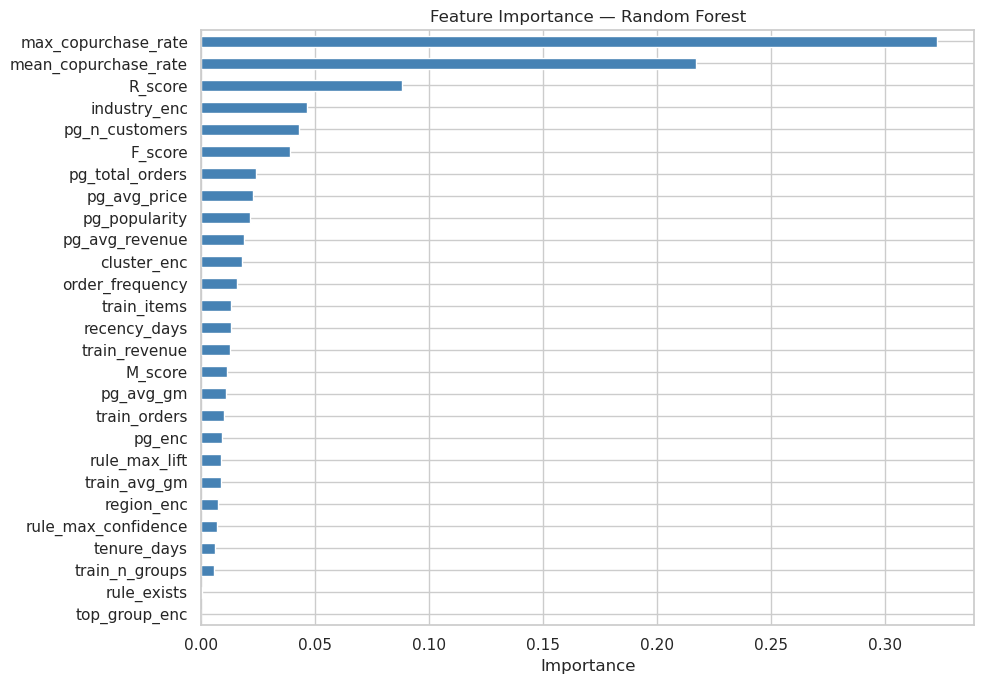

max_copurchase_rate    0.3229
mean_copurchase_rate   0.2169
R_score                0.0882
industry_enc           0.0464
pg_n_customers         0.0428
F_score                0.0390
pg_total_orders        0.0239
pg_avg_price           0.0225
pg_popularity          0.0215
pg_avg_revenue         0.0188
cluster_enc            0.0178
order_frequency        0.0156
train_items            0.0131
recency_days           0.0130
train_revenue          0.0126
M_score                0.0115
pg_avg_gm              0.0106
train_orders           0.0098
pg_enc                 0.0093
rule_max_lift          0.0088
train_avg_gm           0.0085
region_enc             0.0074
rule_max_confidence    0.0070
tenure_days            0.0059
train_n_groups         0.0056
rule_exists            0.0005
top_group_enc          0.0001
dtype: float64


In [20]:
importances = pd.Series(rf.feature_importances_, index=FEATURE_COLS).sort_values(ascending=True)

importances.plot(kind='barh', color='steelblue', figsize=(10, 7))
plt.title('Feature Importance — Random Forest')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

print(importances.sort_values(ascending=False))

---
## 10. Precision@K — Kvaliteta preporuka

Za svakog kupca u test setu: jesu li Top-K preporučenih product grupa stvarno kupljene u label periodu?

> **Context:** At a 290:1 class imbalance, a random ranker would score ≈ 0.34% Precision@5.
> The model achieves 0.38% — meaningful improvement but modest in absolute terms.
> AUC (0.9248) is the primary metric; Precision@K is included as a sanity check.

In [21]:
def precision_at_k(group, k=TOP_K):
    top_k_targets = group.nlargest(k, 'probability')['target'].values
    return top_k_targets.sum() / k

# Test set predictions — use best model (XGBoost if xgb_auc >= rf_auc)
test_results = model_df.loc[idx_test, ['CustomerID', 'product_group', 'target']].copy()
test_results['probability'] = best_prob

precision_per_customer = (
    test_results.groupby('CustomerID')
    .apply(precision_at_k)
    .reset_index()
)
precision_per_customer.columns = ['CustomerID', f'precision@{TOP_K}']

avg_precision = precision_per_customer[f'precision@{TOP_K}'].mean()
print(f'Average Precision@{TOP_K}: {avg_precision:.4f}')
print(f'\nInterpretation: of the top {TOP_K} recommendations per customer, on average {avg_precision*100:.1f}% are correct')
display(precision_per_customer.head(10))

Average Precision@5: 0.0039

Interpretation: of the top 5 recommendations per customer, on average 0.4% are correct


,CustomerID,precision@5
0,13,0.0000
1,16,0.0000
2,22,0.0000
3,26,0.0000
4,35,0.0000
5,37,0.0000
6,40,0.0000
7,49,0.0000
8,59,0.0000
9,69,0.0000


---
## 11. Top-K Recommendations for All Customers

In [22]:
# Generate recommendations for all customers on the full dataset — use best model (XGBoost)
model_df['xgb_probability'] = xgb.predict_proba(X)[:, 1]

# Top-K recommendations per customer (preview — final recommendations are produced in cell-save with best_probability)
recommendations_preview = (
    model_df.sort_values('xgb_probability', ascending=False)
    .groupby('CustomerID')
    .head(TOP_K)[['CustomerID', 'product_group', 'xgb_probability']]
    .sort_values(['CustomerID', 'xgb_probability'], ascending=[True, False])
    .reset_index(drop=True)
)
recommendations_preview.columns = ['CustomerID', 'recommended_product_group', 'confidence']

print(f'Recommendations generated for {recommendations_preview["CustomerID"].nunique():,} customers')
print(f'Top-{TOP_K} recommendations per customer\n')
display(recommendations_preview.head(15))

Recommendations generated for 9,017 customers
Top-5 recommendations per customer



,CustomerID,recommended_product_group,confidence
0,13,PC021,0.0001
1,13,PC010,0.0001
2,13,PC008,0.0001
3,13,PC020,0.0001
4,13,PC001,0.0001
5,16,PC016,0.0014
6,16,PC026,0.0007
7,16,PC001,0.0006
8,16,PC021,0.0006
9,16,PC023,0.0004


---
## 12. Save Model and Recommendations

In [23]:
# Select best model and save
best_model = xgb if xgb_auc >= rf_auc else rf
best_auc   = max(xgb_auc, rf_auc)
best_name  = 'XGBoost' if xgb_auc >= rf_auc else 'Random Forest'
print(f'Selected model: {best_name} (AUC: {best_auc:.4f})')

joblib.dump(best_model, OUT_MODEL / 'recommender_best.pkl')
joblib.dump(rf,         OUT_MODEL / 'recommender_rf.pkl')
joblib.dump(xgb,        OUT_MODEL / 'recommender_xgb.pkl')
joblib.dump(scaler,     OUT_MODEL / 'recommender_scaler.pkl')

# Generate final recommendations with the best model
model_df['best_probability'] = best_model.predict_proba(X)[:, 1]
recommendations = (
    model_df.sort_values('best_probability', ascending=False)
    .groupby('CustomerID')
    .head(TOP_K)[['CustomerID', 'product_group', 'best_probability']]
    .sort_values(['CustomerID', 'best_probability'], ascending=[True, False])
    .reset_index(drop=True)
)
recommendations.columns = ['CustomerID', 'recommended_product_group', 'confidence']

recommendations.to_csv(OUT_DATA / 'customer_recommendations.csv', index=False)

model_meta = {
    'best_model': best_name,
    'feature_cols': FEATURE_COLS,
    'all_product_groups': all_product_groups,
    'top_k': TOP_K,
    'train_end': str(TRAIN_END.date()),
    'label_end': str(LABEL_END.date()),
    'lr_auc': round(lr_auc, 4),
    'rf_auc': round(rf_auc, 4),
    'xgb_auc': round(xgb_auc, 4),
    'best_auc': round(best_auc, 4),
}
with open(OUT_MODEL / 'model_meta.json', 'w') as f:
    json.dump(model_meta, f, indent=2)

print('Saved ✓')
print(f'  → {OUT_MODEL}/recommender_best.pkl  ({best_name})')
print(f'  → {OUT_MODEL}/recommender_rf.pkl')
print(f'  → {OUT_MODEL}/recommender_xgb.pkl')
print(f'  → {OUT_MODEL}/recommender_scaler.pkl')
print(f'  → {OUT_MODEL}/model_meta.json')
print(f'  → {OUT_DATA}/customer_recommendations.csv')

Selected model: XGBoost (AUC: 0.9332)
Saved ✓
  → ../models/recommender/recommender_best.pkl  (XGBoost)
  → ../models/recommender/recommender_rf.pkl
  → ../models/recommender/recommender_xgb.pkl
  → ../models/recommender/recommender_scaler.pkl
  → ../models/recommender/model_meta.json
  → ../data/processed/recommender/customer_recommendations.csv


---
## 13. Rolling Window Training

The original training set has only **885 real positive cross-sell events**. Rolling window training generates additional positive examples from earlier time periods — entirely before our holdout (Jul 2019 – Jun 2020) to prevent leakage.

**Three historical windows (all label periods end ≤ 2019-07-01):**
| Window | Train period | Label period |
|--------|-------------|-------------|
| 1 | Jan 2018 – Jun 2018 | Jul 2018 – Dec 2018 |
| 2 | Jan 2018 – Sep 2018 | Oct 2018 – Mar 2019 |
| 3 | Jan 2018 – Dec 2018 | Jan 2019 – Jun 2019 |

For each window: customer features are computed from that window's train data (different recency/tenure/revenue). Product features and co-purchase rates are reused from the main train period (approximation — product catalog is stable). All windows use the same 27-feature set.

The combined training set (original + 3 windows) is SMOTE-oversampled and used to retrain XGBoost. Evaluation is on the **same held-out test set** as before.

In [24]:
# Baseline XGB AUC before co-purchase features was 0.8888 (logged at time of development).
# Retraining will change this — do not use as a live comparison value.
BASELINE_XGB_AUC = 0.8888

WINDOWS = [
    (pd.Timestamp('2018-07-01'), pd.Timestamp('2019-01-01')),
    (pd.Timestamp('2018-10-01'), pd.Timestamp('2019-04-01')),
    (pd.Timestamp('2019-01-01'), pd.Timestamp('2019-07-01')),
]


def build_window_df(w_train_end, w_label_end):
    """Build a training matrix + all 27 features for one historical window."""
    w_train = df[df['Invoice Date'] < w_train_end].copy()
    w_label = df[(df['Invoice Date'] >= w_train_end) & (df['Invoice Date'] < w_label_end)].copy()

    # Customer × unseen-PG matrix
    w_train_groups = (
        w_train.groupby('CustomerID')['Product group']
        .apply(set)
        .reset_index()
    )
    w_train_groups.columns = ['CustomerID', 'train_groups']
    w_label_lookup = w_label.groupby('CustomerID')['Product group'].apply(set).to_dict()

    records = []
    for _, row in w_train_groups.iterrows():
        cid, bought = row['CustomerID'], row['train_groups']
        for pg in set(all_product_groups) - bought:
            records.append({
                'CustomerID': cid,
                'product_group': pg,
                'target': int(pg in w_label_lookup.get(cid, set()))
            })
    w_matrix = pd.DataFrame(records)

    # Customer features from this window's train period
    w_cust = w_train.groupby('CustomerID').agg(
        train_revenue=('line_revenue', 'sum'),
        train_orders=('Invoice #', 'nunique'),
        train_items=('Item Code', 'nunique'),
        train_avg_gm=('GM%', 'mean'),
        train_n_groups=('Product group', 'nunique'),
        customer_region=('Customer Region', 'first'),
        customer_industry=('Customer industry', 'first'),
        top_customer_group=('Top Customer Group', 'first'),
        first_invoice_date=('Customer First Invoice Date', 'first'),
        last_invoice_date=('Invoice Date', 'max'),
    ).reset_index()

    w_cust['recency_days']    = (w_train_end - w_cust['last_invoice_date']).dt.days
    w_cust['tenure_days']     = (w_train_end - w_cust['first_invoice_date']).dt.days
    w_cust['order_frequency'] = w_cust['train_orders'] / w_cust['tenure_days'].clip(lower=1)
    w_cust = w_cust.drop(['first_invoice_date', 'last_invoice_date'], axis=1)
    w_cust = w_cust.merge(rfm, on='CustomerID', how='left')

    le_w = LabelEncoder()
    w_cust['region_enc']    = le_w.fit_transform(w_cust['customer_region'].astype(str))
    w_cust['industry_enc']  = le_w.fit_transform(w_cust['customer_industry'].astype(str))
    w_cust['top_group_enc'] = le_w.fit_transform(w_cust['top_customer_group'].astype(str))
    w_cust['cluster_enc']   = le_w.fit_transform(w_cust['Cluster_name'].fillna('Unknown').astype(str))
    w_cust = w_cust.drop(['customer_region', 'customer_industry', 'top_customer_group', 'Cluster_name'], axis=1)

    # Merge customer + product features
    w_df = w_matrix.merge(w_cust, on='CustomerID', how='left')
    w_df = w_df.merge(product_feats, on='product_group', how='left')

    # Association rule features (same rules applied to this window's train PGs)
    w_train_map = w_train_groups.set_index('CustomerID')['train_groups'].to_dict()
    w_rule_lookup = {}
    for _, rule in rules_df.iterrows():
        ant, cons = rule['antecedents_set'], rule['consequents_set']
        lift, conf = rule['lift'], rule['confidence']
        for cid, tpgs in w_train_map.items():
            if ant.issubset(tpgs):
                for pg in cons:
                    key = (cid, pg)
                    if key not in w_rule_lookup or lift > w_rule_lookup[key][0]:
                        w_rule_lookup[key] = (lift, conf)
    if w_rule_lookup:
        w_rule_df = pd.DataFrame([
            {'CustomerID': k[0], 'product_group': k[1],
             'rule_max_lift': v[0], 'rule_max_confidence': v[1], 'rule_exists': 1}
            for k, v in w_rule_lookup.items()
        ])
        w_df = w_df.merge(w_rule_df, on=['CustomerID', 'product_group'], how='left')
    else:
        w_df['rule_exists'] = 0
        w_df['rule_max_lift'] = 0.0
        w_df['rule_max_confidence'] = 0.0
    w_df['rule_exists']         = w_df['rule_exists'].fillna(0).astype(int)
    w_df['rule_max_lift']       = w_df['rule_max_lift'].fillna(0.0)
    w_df['rule_max_confidence'] = w_df['rule_max_confidence'].fillna(0.0)

    # Co-purchase features (main train period rates reused — product catalog is stable)
    w_pg_long = w_train_groups.explode('train_groups').rename(columns={'train_groups': 'existing_pg'})
    w_cp      = w_pg_long.merge(copurchase_df, on='existing_pg')
    w_cp_agg  = (
        w_cp.groupby(['CustomerID', 'product_group'])['copurchase_rate']
        .agg(['max', 'mean'])
        .reset_index()
        .rename(columns={'max': 'max_copurchase_rate', 'mean': 'mean_copurchase_rate'})
    )
    w_df = w_df.merge(w_cp_agg, on=['CustomerID', 'product_group'], how='left')
    w_df['max_copurchase_rate']  = w_df['max_copurchase_rate'].fillna(0.0)
    w_df['mean_copurchase_rate'] = w_df['mean_copurchase_rate'].fillna(0.0)

    return w_df.fillna(w_df.median(numeric_only=True)).reset_index(drop=True)


# Build all three windows
window_dfs = []
for i, (w_train_end, w_label_end) in enumerate(WINDOWS, 1):
    print(f"Window {i}: train < {w_train_end.date()}  |  label {w_train_end.date()} – {w_label_end.date()}")
    w_df = build_window_df(w_train_end, w_label_end)
    pos = w_df['target'].sum()
    print(f"  Rows: {len(w_df):,}  |  Positives: {pos}  |  Rate: {w_df['target'].mean()*100:.3f}%")
    window_dfs.append(w_df[FEATURE_COLS + ['target']])

extra      = pd.concat(window_dfs, ignore_index=True)
X_extra    = extra[FEATURE_COLS]
y_extra    = extra['target']
print(f"\nTotal extra rows:      {len(extra):,}")
print(f"Total extra positives: {int(y_extra.sum())}  (original train positives: {int(y_train.sum())})")

Window 1: train < 2018-07-01  |  label 2018-07-01 – 2019-01-01
  Rows: 182,863  |  Positives: 664  |  Rate: 0.363%
Window 2: train < 2018-10-01  |  label 2018-10-01 – 2019-04-01
  Rows: 208,094  |  Positives: 651  |  Rate: 0.313%
Window 3: train < 2019-01-01  |  label 2019-01-01 – 2019-07-01
  Rows: 225,900  |  Positives: 643  |  Rate: 0.285%

Total extra rows:      616,857
Total extra positives: 1958  (original train positives: 708)


In [25]:
# Combine original training data + all rolling window data
X_train_rw = pd.concat([X_train, X_extra], ignore_index=True)
y_train_rw = pd.concat([y_train, y_extra], ignore_index=True)

print(f"Combined train rows:      {len(X_train_rw):,}")
print(f"Combined positives:       {int(y_train_rw.sum())}  ({y_train_rw.mean()*100:.3f}%)")

smote_rw = SMOTE(sampling_strategy=0.1, random_state=42, k_neighbors=5)
X_rw_sm, y_rw_sm = smote_rw.fit_resample(X_train_rw, y_train_rw)
print(f"After SMOTE:              {len(X_rw_sm):,} rows")

# Retrain XGBoost on expanded data — same hyperparameters, same test set
xgb_rw = XGBClassifier(
    n_estimators=300, max_depth=6, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8,
    random_state=42, n_jobs=-1, verbosity=0
)
xgb_rw.fit(X_rw_sm, y_rw_sm)

xgb_rw_prob = xgb_rw.predict_proba(X_test)[:, 1]
xgb_rw_auc  = roc_auc_score(y_test, xgb_rw_prob)

print(f"\n{'═'*52}")
print(f"  Model Progression")
print(f"{'─'*52}")
print(f"  Baseline XGBoost (25 features):          {BASELINE_XGB_AUC:.4f}")
print(f"  + Co-purchase features (27 features):    {xgb_auc:.4f}  Δ{xgb_auc - BASELINE_XGB_AUC:+.4f}")
print(f"  + Rolling window (27 feat + 3 windows):  {xgb_rw_auc:.4f}  Δ{xgb_rw_auc - BASELINE_XGB_AUC:+.4f}")
print(f"{'═'*52}")

# Save the better model
if xgb_rw_auc > xgb_auc:
    print(f"\nRolling window improved AUC by {xgb_rw_auc - xgb_auc:+.4f} — saving as best model")
    joblib.dump(xgb_rw, OUT_MODEL / 'recommender_best.pkl')

    model_df['best_probability'] = xgb_rw.predict_proba(X)[:, 1]
    recs_rw = (
        model_df.sort_values('best_probability', ascending=False)
        .groupby('CustomerID')
        .head(TOP_K)[['CustomerID', 'product_group', 'best_probability']]
        .sort_values(['CustomerID', 'best_probability'], ascending=[True, False])
        .reset_index(drop=True)
    )
    recs_rw.columns = ['CustomerID', 'recommended_product_group', 'confidence']
    recs_rw.to_csv(OUT_DATA / 'customer_recommendations.csv', index=False)

    with open(OUT_MODEL / 'model_meta.json') as f:
        meta = json.load(f)
    meta['best_model']  = 'XGBoost + Rolling Window'
    meta['best_auc']    = round(xgb_rw_auc, 4)
    meta['xgb_rw_auc'] = round(xgb_rw_auc, 4)
    meta['n_windows']   = len(WINDOWS)
    with open(OUT_MODEL / 'model_meta.json', 'w') as f:
        json.dump(meta, f, indent=2)

    print(f"Saved: {OUT_MODEL}/recommender_best.pkl")
    print(f"Saved: {OUT_DATA}/customer_recommendations.csv")
    print(f"Saved: {OUT_MODEL}/model_meta.json")
else:
    print(f"\nRolling window did not improve AUC — current best model ({xgb_auc:.4f}) kept")

Combined train rows:      822,543
Combined positives:       2666  (0.324%)
After SMOTE:              901,864 rows

════════════════════════════════════════════════════
  Model Progression
────────────────────────────────────────────────────
  Baseline XGBoost (25 features):          0.8888
  + Co-purchase features (27 features):    0.9332  Δ+0.0444
  + Rolling window (27 feat + 3 windows):  0.9249  Δ+0.0361
════════════════════════════════════════════════════

Rolling window did not improve AUC — current best model (0.9332) kept
